# 3D reconstruction from 2D images - step-by-step walkthrough

This notebook runs the pipeline from the seminar **one stage at a time** so you can see what each step produces.
It uses the modules in `src/recon3d/`, so everything here is also available from the command line.

| # | Stage | Module |
|---|---|---|
| 1 | Image collection | `images.py` |
| 2 | Feature extraction | `features.py` |
| 3 | Feature matching | `matching.py` |
| 4 | Structure from Motion | `sfm.py` |
| 5 | Dense point cloud | `dense.py` |
| 6-7 | Mesh reconstruction + refinement | `mesh.py` |
| 8 | Mesh texturing | `texture.py` |

**Run it:** select your `.venv` as the kernel (top right in VS Code) and *Run All*. By default it uses the built-in
synthetic test photos. To use your own, change `IMAGE_DIR` in the first code cell to `"../data/images"`.

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import open3d as o3d

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from recon3d import images, features, matching, sfm, dense, mesh, texture, render
from recon3d.synthetic import make_dataset

# ---- settings you can change -------------------------------------------------
IMAGE_DIR = ROOT / "data" / "synthetic"   # change to ROOT / "data" / "images" for your own photos
MAX_DIM = 1000       # downscale photos so the longest side is this many pixels (smaller = faster)
WINDOW = 6           # photos taken in order around the object: only match neighbours within this many shots
# ------------------------------------------------------------------------------

if IMAGE_DIR.name == "synthetic" and not (IMAGE_DIR / "ground_truth_camera_centers.npy").exists():
    make_dataset(IMAGE_DIR, n_images=36)      # fake photos of a textured cube, for testing
print("using photos in", IMAGE_DIR)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


using photos in /tmp/work/3d-reconstruction/data/synthetic


## Step 1 - Image collection
Load the photos and check them against the capture rules from the assignment (at least 20, sharp, same size).
Then build the **camera matrix** `K`. A pixel `(u, v)` and a 3D point in camera coordinates `(X, Y, Z)` are related by
`u = f*X/Z + cx`, `v = f*Y/Z + cy`. We take `f` from the photo's EXIF data when it exists.

36 photos, 1000 x 750 px, focal length ~ 1200 px
camera matrix K =
 [[1.20e+03 0.00e+00 5.00e+02]
 [0.00e+00 1.20e+03 3.75e+02]
 [0.00e+00 0.00e+00 1.00e+00]]


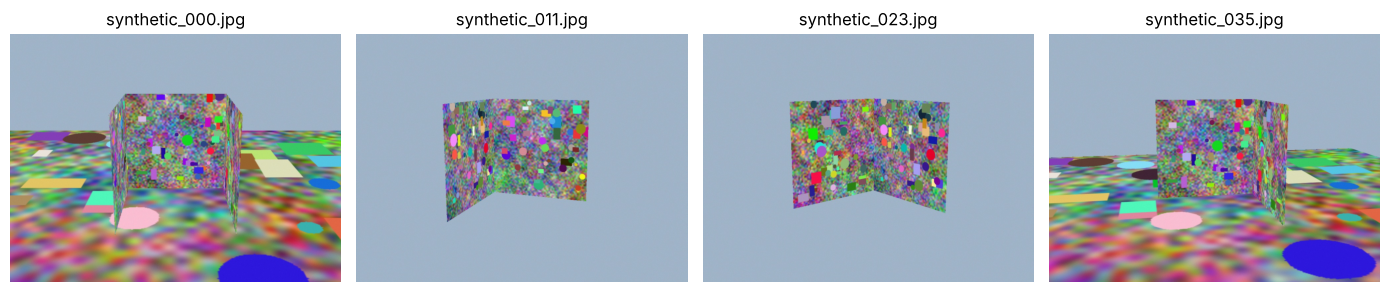

In [2]:
paths = images.list_images(IMAGE_DIR)
for w in images.check_images(IMAGE_DIR):
    print("WARNING:", w)
imgs = [images.load_image(p, MAX_DIM) for p in paths]
h, w = imgs[0].shape[:2]
f = images.focal_pixels(paths[0], w, h)
K = np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1.0]])
print(f"{len(imgs)} photos, {w} x {h} px, focal length ~ {f:.0f} px")
print("camera matrix K =\n", K.round(1))

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
for ax, k in zip(axes, np.linspace(0, len(imgs) - 1, 4).astype(int)):
    ax.imshow(imgs[k][:, :, ::-1]); ax.set_title(paths[k].name); ax.axis("off")
plt.tight_layout(); plt.show()

## Step 2 - Feature extraction
SIFT finds *keypoints* - corners and blobs that look the same from different viewpoints - and describes each with
128 numbers (a *descriptor*). This is the "Feature detections" slide.

keypoints per photo (first 5): [2448, 2746, 3183, 3337, 2997]
descriptor shape for photo 0: (2448, 128)


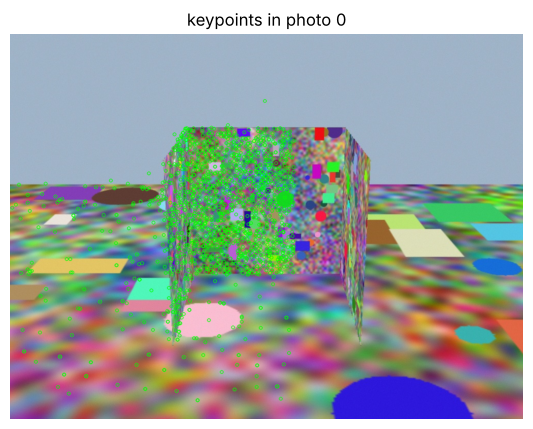

In [3]:
feats = [features.extract(im, n_features=4000) for im in imgs]
print("keypoints per photo (first 5):", [len(x.xy) for x in feats[:5]])
print("descriptor shape for photo 0:", feats[0].desc.shape)

plt.figure(figsize=(7, 5))
plt.imshow(features.draw_keypoints(imgs[0], feats[0], max_pts=1500)[:, :, ::-1])
plt.title("keypoints in photo 0"); plt.axis("off"); plt.show()

## Step 3 - Feature matching
For two photos, find which keypoint in photo B is the same physical point as each keypoint in photo A
(*corresponding pixels*). Two filters:

1. **Ratio test + mutual check** - keep a match only if it is clearly better than the runner-up and agrees both ways.
2. **Epipolar check (RANSAC)** - a true match must lie on the *epipolar line* predicted by one camera geometry
   (the epipolar geometry slide). Matches that disagree are outliers.

keypoints: 2448 / 3183
after ratio test + mutual check: 1127 matches
after epipolar (RANSAC) check:    1084 matches


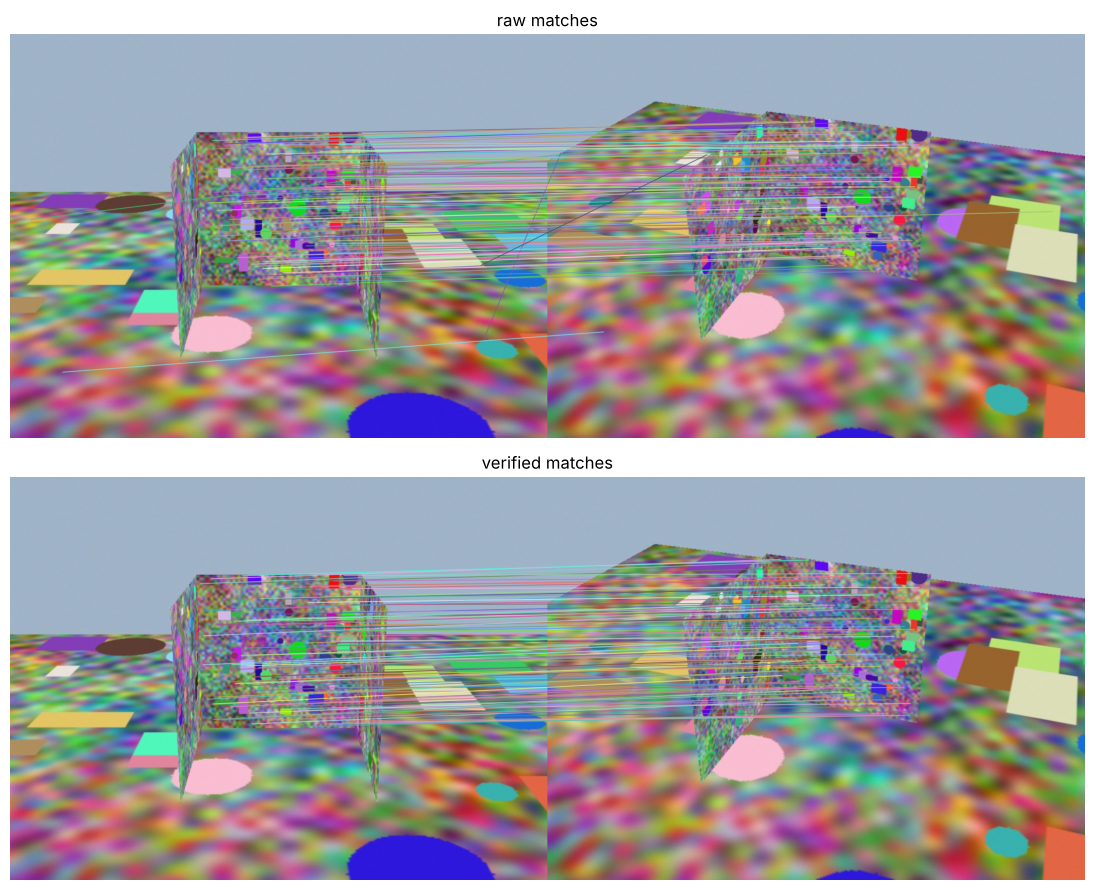

In [4]:
A, B = 0, 2
ia, ib = matching.match_pair(feats[A], feats[B])
ja, jb, F = matching.verify_pair(feats[A], feats[B], ia, ib)
print(f"keypoints: {len(feats[A].xy)} / {len(feats[B].xy)}")
print(f"after ratio test + mutual check: {len(ia)} matches")
print(f"after epipolar (RANSAC) check:    {len(ja)} matches")

fig, ax = plt.subplots(2, 1, figsize=(12, 9))
ax[0].imshow(matching.draw_matches(imgs[A], imgs[B], feats[A], feats[B], ia, ib, 100)[:, :, ::-1]); ax[0].set_title("raw matches"); ax[0].axis("off")
ax[1].imshow(matching.draw_matches(imgs[A], imgs[B], feats[A], feats[B], ja, jb, 100)[:, :, ::-1]); ax[1].set_title("verified matches"); ax[1].axis("off")
plt.tight_layout(); plt.show()

204 photo pairs with enough verified matches


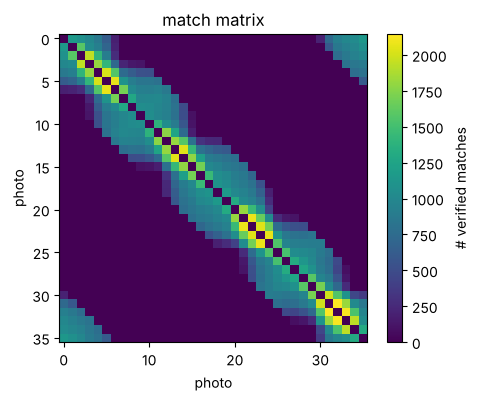

In [5]:
# match all neighbouring pairs (this is the slow part - about a minute for 36 photos)
all_matches = matching.match_all(feats, window=WINDOW)
print(len(all_matches), "photo pairs with enough verified matches")

# how connected is the photo set? (a good capture has a bright band around the diagonal)
n = len(imgs)
conn = np.zeros((n, n))
for (i, j), (a, b) in all_matches.items():
    conn[i, j] = conn[j, i] = len(a)
plt.figure(figsize=(5, 4)); plt.imshow(conn, cmap="viridis"); plt.colorbar(label="# verified matches")
plt.xlabel("photo"); plt.ylabel("photo"); plt.title("match matrix"); plt.show()

## Step 4 - Structure from Motion
Now the key idea: if the same point `X` is seen at pixel `x1` in camera 1 and `x2` in camera 2, the two viewing rays
intersect at `X` (the "compute 3D coordinates" slide). SfM does this for thousands of points *while also working out where
the cameras are*:

1. link matches into **tracks** (one physical point seen in many photos),
2. start from the best pair: relative pose from the **essential matrix**, then triangulate,
3. add one photo at a time using **PnP** (known 3D points -> pose),
4. **bundle adjustment** refines all cameras and points together to minimise reprojection error.

In [6]:
rec = sfm.run_sfm(feats, all_matches, K, verbose=True)
print()
print(f"cameras placed: {len(rec.poses)} / {len(imgs)}")
print(f"3D points:      {len(rec.points)}")
print(f"mean reprojection error: {rec.mean_reproj_error():.2f} px   (below 1 px is good)")

  12945 tracks


  initial pair (31,32) -> 2088 points


  registered image  33 (1614 PnP inliers, +685 points, 3/36 cams)
  registered image  30 (1860 PnP inliers, +444 points, 4/36 cams)


  registered image  34 (1828 PnP inliers, +310 points, 5/36 cams)
  registered image  29 (1589 PnP inliers, +242 points, 6/36 cams)
  registered image  35 (1315 PnP inliers, +168 points, 7/36 cams)
  registered image  28 (1244 PnP inliers, +481 points, 8/36 cams)


  registered image  27 (1226 PnP inliers, +226 points, 9/36 cams)
  registered image  26 (1305 PnP inliers, +241 points, 10/36 cams)
  registered image  25 (1319 PnP inliers, +405 points, 11/36 cams)
  registered image  24 (1336 PnP inliers, +438 points, 12/36 cams)


...

  registered image  13 (1664 PnP inliers, +172 points, 25/36 cams)
  registered image  14 (1770 PnP inliers, +539 points, 26/36 cams)
  registered image  12 (2016 PnP inliers, +278 points, 27/36 cams)
  registered image  15 (1881 PnP inliers, +187 points, 28/36 cams)


  registered image  11 (1794 PnP inliers, +217 points, 29/36 cams)
  registered image   7 (1800 PnP inliers, +199 points, 30/36 cams)
  registered image  16 (1752 PnP inliers, +266 points, 31/36 cams)
  registered image  17 (1478 PnP inliers, +209 points, 32/36 cams)


  registered image  10 (1418 PnP inliers, +159 points, 33/36 cams)
  registered image   8 (1418 PnP inliers, +179 points, 34/36 cams)
  registered image  18 (1287 PnP inliers, +102 points, 35/36 cams)
  registered image   9 (1215 PnP inliers, +38 points, 36/36 cams)


  final: 36 cameras, 12854 points, mean reprojection error 0.22px

cameras placed: 36 / 36
3D points:      12854


mean reprojection error: 0.22 px   (below 1 px is good)


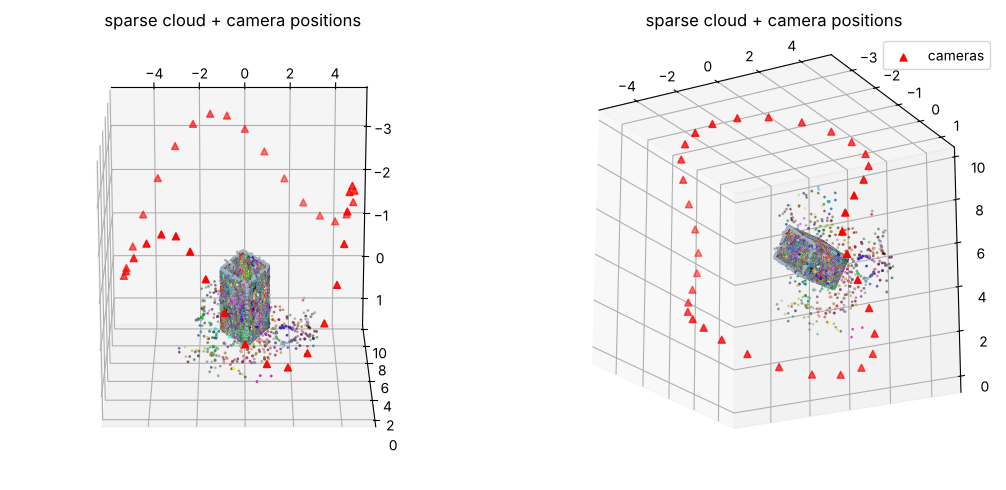

In [7]:
ids, sparse = rec.point_array()
centers = np.array([c.ravel() for c in rec.centers().values()])
cols = dense._sparse_colors(rec, imgs, ids)

fig = plt.figure(figsize=(11, 5))
for k, (elev, azim) in enumerate([(-70, -90), (-20, -60)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    keep = np.linalg.norm(sparse - np.median(sparse, 0), axis=1) < 3 * np.percentile(np.linalg.norm(sparse - np.median(sparse, 0), axis=1), 80)
    ax.scatter(*sparse[keep].T, c=cols[keep], s=1)
    ax.scatter(*centers.T, c="red", s=25, marker="^", label="cameras")
    ax.view_init(elev=elev, azim=azim); ax.set_title("sparse cloud + camera positions")
    ax.set_box_aspect((1, 1, 1))
ax.legend(); plt.tight_layout(); plt.show()

**Check against the truth (synthetic data only).** The synthetic generator saved where it really placed the cameras, so we can
measure how accurate SfM is. SfM has an unknown overall scale/rotation, so we first align the two sets of positions.

In [8]:
truth_file = IMAGE_DIR / "ground_truth_camera_centers.npy"
if truth_file.exists():
    truth = np.load(truth_file)
    cam_ids = sorted(rec.poses)
    est = np.array([rec.centers()[i].ravel() for i in cam_ids])
    tru = truth[cam_ids]
    mu_e, mu_t = est.mean(0), tru.mean(0)
    U, sig, Vt = np.linalg.svd((tru - mu_t).T @ (est - mu_e) / len(est))
    E = np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))]); R = U @ E @ Vt
    s = (sig * np.diag(E)).sum() / (est - mu_e).var(0).sum()
    aligned = (s * (R @ (est - mu_e).T)).T + mu_t
    err = np.linalg.norm(aligned - tru, axis=1)
    radius = np.linalg.norm(tru - mu_t, axis=1).mean()
    print(f"mean camera position error: {err.mean():.3f} units = {100 * err.mean() / radius:.2f}% of the orbit radius")
else:
    print("No ground truth for real photos - judge quality by reprojection error and by how the model looks.")

mean camera position error: 0.010 units = 0.30% of the orbit radius


## Step 5 - Dense point cloud
SfM only reconstructs points that had a keypoint. To fill in surfaces we run **stereo** on neighbouring camera pairs:
virtually rotate both cameras so matching pixels share an image row (*rectification*), compute a **disparity** for every
pixel, and convert to depth with `Z = f * baseline / disparity`.

stereo pair (10, 11): 14228 3D points


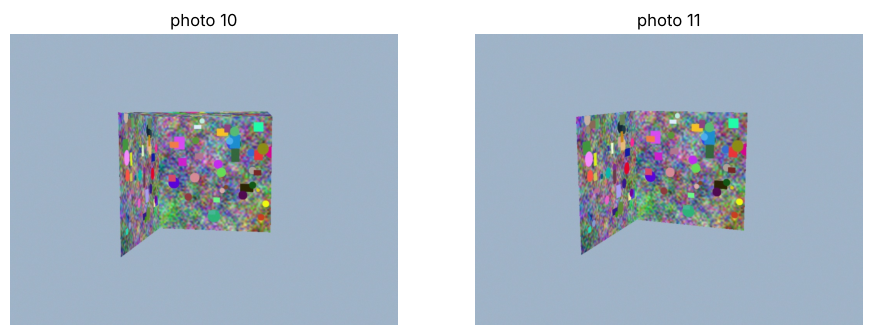

In [9]:
i, j = 10, 11
p, c = dense.stereo_pair(rec, imgs, i, j)
print(f"stereo pair ({i}, {j}): {len(p)} 3D points")

# the idea in one picture: nearby cameras -> the same scene shifted sideways
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(imgs[i][:, :, ::-1]); ax[0].set_title(f"photo {i}"); ax[0].axis("off")
ax[1].imshow(imgs[j][:, :, ::-1]); ax[1].set_title(f"photo {j}"); ax[1].axis("off")
plt.show()

dense cloud: 348,850 points  (sparse had 12,854)


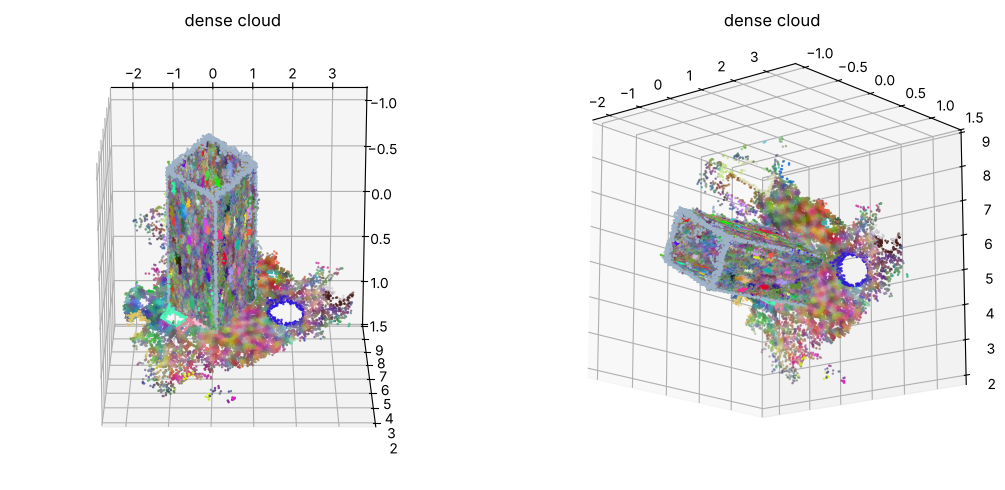

In [10]:
pcd = dense.dense_cloud(rec, imgs, verbose=False)
print(f"dense cloud: {len(pcd.points):,} points  (sparse had {len(rec.points):,})")

P, Cc = np.asarray(pcd.points), np.asarray(pcd.colors)
sel = np.random.default_rng(0).choice(len(P), min(60000, len(P)), replace=False)
fig = plt.figure(figsize=(11, 5))
for k, (elev, azim) in enumerate([(-70, -90), (-15, -50)]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.scatter(*P[sel].T, c=Cc[sel], s=0.6); ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 1)); ax.set_title("dense cloud")
plt.tight_layout(); plt.show()

## Steps 6-7 - Mesh reconstruction and refinement
A point cloud has no surface. **Poisson surface reconstruction** fits a smooth watertight surface to the points (using their
estimated normals), then we trim made-up regions, remove floating fragments, simplify and smooth.

In [11]:
centers_list = list(rec.centers().values())
raw = mesh.reconstruct_mesh(pcd, centers_list, depth=8)
print(f"raw Poisson mesh: {len(raw.vertices):,} vertices, {len(raw.triangles):,} triangles")
ref = mesh.refine_mesh(raw)
print(f"refined mesh:     {len(ref.vertices):,} vertices, {len(ref.triangles):,} triangles")

raw Poisson mesh: 60,879 vertices, 120,515 triangles


refined mesh:     59,286 vertices, 117,443 triangles


## Step 8 - Mesh texturing
Each vertex takes its colour from the photos that see it most face-on.

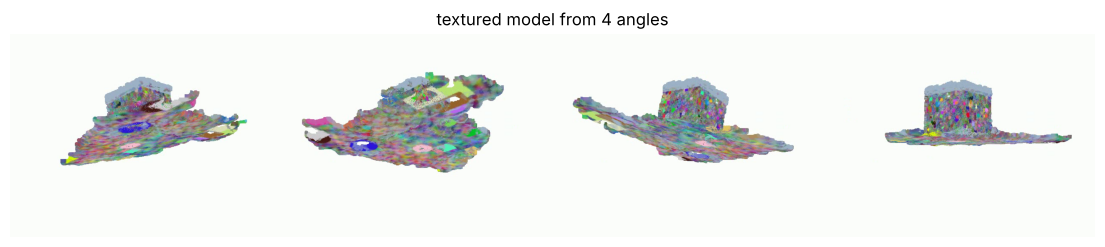

In [12]:
tex = texture.colorize_mesh(ref, rec, imgs)

# render a few views with the built-in turntable renderer
views = []
for k in range(4):
    render.turntable(tex, "_tmp.mp4", seconds=4, fps=1, size=(640, 480))
    cap = cv2.VideoCapture("_tmp.mp4"); cap.set(cv2.CAP_PROP_POS_FRAMES, k); ok, fr = cap.read(); cap.release()
    views.append(fr)
os.remove("_tmp.mp4")
plt.figure(figsize=(14, 3.6)); plt.imshow(cv2.hconcat(views)[:, :, ::-1]); plt.axis("off"); plt.title("textured model from 4 angles"); plt.show()

## Save the results
Writes the mesh (open in MeshLab / Blender) and the turntable video - the assignment's deliverable.

In [13]:
OUT = ROOT / "output" / "notebook_run"
OUT.mkdir(parents=True, exist_ok=True)
o3d.io.write_point_cloud(str(OUT / "dense.ply"), pcd)
o3d.io.write_triangle_mesh(str(OUT / "model.ply"), tex)
render.turntable(tex, str(OUT / "model_turntable.mp4"))
print("saved to", OUT)
for f_ in sorted(OUT.iterdir()):
    print(f"  {f_.name:22s} {f_.stat().st_size/1e6:6.1f} MB")

saved to /tmp/work/3d-reconstruction/output/notebook_run
  dense.ply                 9.4 MB
  model.ply                 4.6 MB
  model_turntable.mp4       7.0 MB


## Things to try
* Change `MAX_DIM` to 600 and to 1600: how do speed and quality change?
* Delete half the photos (`paths = paths[::2]`) and re-run: what breaks first?
* Point `IMAGE_DIR` at your own photos. Which capture rule did you break when SfM places fewer cameras?
* Compare the final model with the Polycam version of the same photos.